<a href="https://colab.research.google.com/github/naiknawarekartik95-cloud/Sales-Data-Filter-Report-Engine-/blob/main/sales_report_engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3: Sales Data Filter & Report Engine
Simulate a year of sales for 10 stores and build a **query engine** that filters records and generates reports using only NumPy.

**NumPy topics:** `arange`, `linspace`, `random`, `reshape`, boolean masking (`&`, `|`, `~`), fancy indexing, 2D slicing

## Step 1: Setup and data creation

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)  # reproducible results

N_STORES, N_MONTHS = 10, 12
months = np.arange(1, 13)                      # month numbers 1..12
month_names = np.array(['Jan','Feb','Mar','Apr','May','Jun',
                        'Jul','Aug','Sep','Oct','Nov','Dec'])
stores = np.arange(1, N_STORES + 1)            # store IDs 1..10

# Sales in INR thousands, shape (10 stores, 12 months)
sales = np.random.randint(200, 1000, N_STORES * N_MONTHS).reshape(N_STORES, N_MONTHS)

print('Shape:', sales.shape, '| ndim:', sales.ndim, '| dtype:', sales.dtype)
print(sales[:3])

Shape: (10, 12) | ndim: 2 | dtype: int64
[[302 635 470 306 271 900 220 814 321 666 414 530]
 [658 287 572 299 863 330 861 508 969 543 691 613]
 [585 391 476 360 659 513 221 452 947 760 674 258]]


## Step 2: Slicing quarters and individual stores

In [2]:
Q1, Q2, Q3, Q4 = sales[:, 0:3], sales[:, 3:6], sales[:, 6:9], sales[:, 9:12]

store_3 = sales[2]            # one store, all months
last_month = sales[:, -1]     # all stores, December
first_5_stores_H1 = sales[:5, :6]

quarter_totals = np.array([q.sum() for q in (Q1, Q2, Q3, Q4)])
for i, t in enumerate(quarter_totals, 1):
    print(f'Q{i} total: {t:,}')
print('Store 3 yearly total:', store_3.sum())

Q1 total: 16,074
Q2 total: 17,873
Q3 total: 18,537
Q4 total: 17,787
Store 3 yearly total: 6296


## Step 3: Targets with `linspace` and mask queries

In [3]:
# Growth target: starts at 450 and grows linearly to 700 by December
monthly_target = np.linspace(450, 700, N_MONTHS)

above_target = sales > monthly_target               # broadcasting (10,12) vs (12,)
print('Store-months above target:', above_target.sum(), 'of', sales.size)

store_avg = sales.mean(axis=1)
below_avg_stores = stores[store_avg < sales.mean()]
print('Stores below overall average:', below_avg_stores)

# Combined conditions with & | ~
strong = (sales > monthly_target) & (sales > 600)           # AND
weak_or_low = (sales < 300) | (sales < monthly_target * 0.6) # OR
not_above = ~above_target                                    # NOT
print('Strong months:', strong.sum(), '| Weak months:', weak_or_low.sum(), '| Missed target:', not_above.sum())

Store-months above target: 62 of 120
Stores below overall average: [1 3 5 6 9]
Strong months: 53 | Weak months: 25 | Missed target: 58


## Step 4: Fancy indexing

In [4]:
picked = sales[[1, 4, 7]]                       # stores 2, 5, 8 (0-indexed rows)

month_totals = sales.sum(axis=0)
best_3_months = np.argsort(month_totals)[-3:][::-1]   # indices of top 3 months
print('Best 3 months:', month_names[best_3_months], month_totals[best_3_months])

# Selected stores x best months using np.ix_
sub = sales[np.ix_([1, 4, 7], best_3_months)]
print(sub)

Best 3 months: ['Aug' 'May' 'Nov'] [7219 6502 6501]
[[508 863 691]
 [515 473 976]
 [901 661 919]]


## Step 5: Query engine and report

In [5]:
def query(min_sales=None, max_sales=None, store_ids=None, month_nums=None):
    """Return (store_id, month_name, sales) rows matching ALL given filters."""
    mask = np.ones(sales.shape, dtype=bool)
    if min_sales is not None: mask &= sales >= min_sales
    if max_sales is not None: mask &= sales <= max_sales
    if store_ids is not None: mask &= np.isin(stores, store_ids)[:, None]
    if month_nums is not None: mask &= np.isin(months, month_nums)[None, :]
    r, c = np.where(mask)
    return np.column_stack((stores[r], month_names[c], sales[r, c]))

print(query(min_sales=900))
print(query(store_ids=[1, 4, 7], month_nums=[1, 2, 3], min_sales=500)[:5])

[['1' 'Jun' '900']
 ['2' 'Sep' '969']
 ['3' 'Sep' '947']
 ['4' 'May' '982']
 ['5' 'Nov' '976']
 ['6' 'Aug' '975']
 ['7' 'Jun' '971']
 ['7' 'Aug' '902']
 ['7' 'Oct' '929']
 ['8' 'Jun' '926']
 ['8' 'Aug' '901']
 ['8' 'Oct' '924']
 ['8' 'Nov' '919']
 ['8' 'Dec' '948']
 ['9' 'Mar' '991']
 ['9' 'May' '963']]
[['1' 'Feb' '635']
 ['4' 'Jan' '710']
 ['4' 'Feb' '881']
 ['4' 'Mar' '675']
 ['7' 'Jan' '587']]


In [6]:
def report():
    print('=' * 52)
    print('ANNUAL SALES REPORT (INR thousands)')
    print('=' * 52)
    print('\nMonthly totals vs target (sum of all stores):')
    for m, tot, tgt in zip(month_names, month_totals, monthly_target * N_STORES):
        flag = 'OK ' if tot >= tgt else 'LOW'
        print(f'  {m}: {tot:6d}  target {tgt:7.0f}  [{flag}]')
    print('\nStore-wise totals:')
    for s, tot in zip(stores, sales.sum(axis=1)):
        print(f'  Store {s:2d}: {tot:6d}')
    top = stores[sales.sum(axis=1).argmax()]
    print(f'\nTop store: {top} | Best month: {month_names[month_totals.argmax()]}')

report()

ANNUAL SALES REPORT (INR thousands)

Monthly totals vs target (sum of all stores):
  Jan:   5948  target    4500  [OK ]
  Feb:   5044  target    4727  [OK ]
  Mar:   5082  target    4955  [OK ]
  Apr:   5479  target    5182  [OK ]
  May:   6502  target    5409  [OK ]
  Jun:   5892  target    5636  [OK ]
  Jul:   5740  target    5864  [LOW]
  Aug:   7219  target    6091  [OK ]
  Sep:   5578  target    6318  [LOW]
  Oct:   6058  target    6545  [LOW]
  Nov:   6501  target    6773  [LOW]
  Dec:   5228  target    7000  [LOW]

Store-wise totals:
  Store  1:   5849
  Store  2:   7194
  Store  3:   6296
  Store  4:   8427
  Store  5:   6666
  Store  6:   6804
  Store  7:   7642
  Store  8:   8220
  Store  9:   5891
  Store 10:   7282

Top store: 4 | Best month: Aug


## Step 6: Visualise

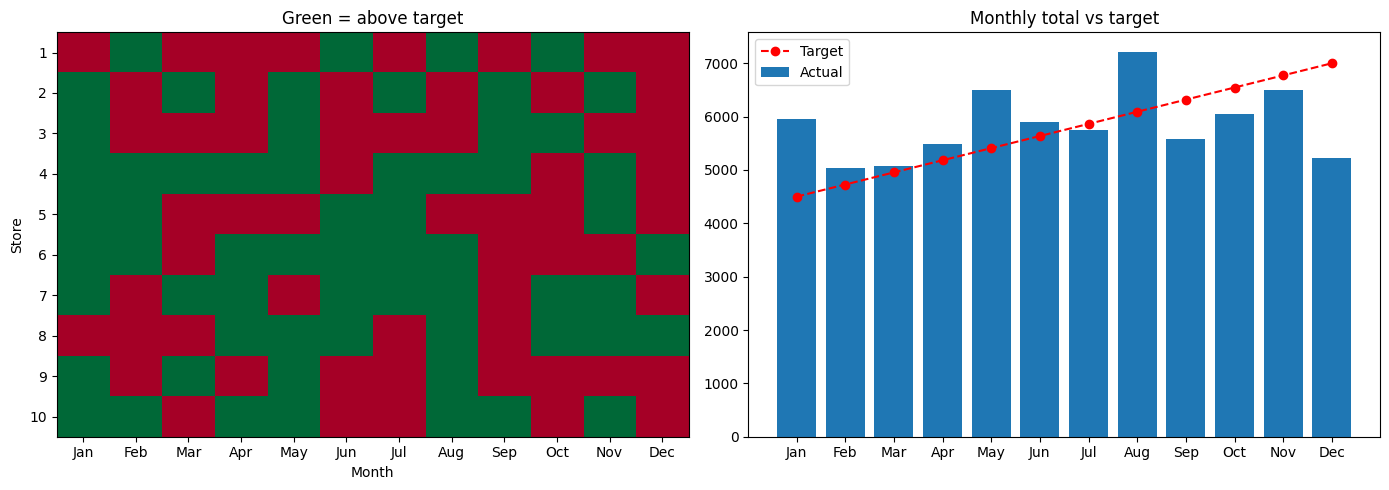

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

im = ax[0].imshow(above_target, cmap='RdYlGn', aspect='auto')
ax[0].set_xticks(range(12)); ax[0].set_xticklabels(month_names)
ax[0].set_yticks(range(10)); ax[0].set_yticklabels(stores)
ax[0].set_title('Green = above target'); ax[0].set_xlabel('Month'); ax[0].set_ylabel('Store')

ax[1].bar(month_names, month_totals, label='Actual')
ax[1].plot(month_names, monthly_target * N_STORES, 'r--o', label='Target')
ax[1].set_title('Monthly total vs target'); ax[1].legend()

plt.tight_layout(); plt.savefig('sales_report.png', dpi=120); plt.show()

## Conclusion
Built a query engine with boolean masks (`&`, `|`, `~`), fancy indexing and 2D slicing on a 10x12 sales matrix.

**Ideas to extend:** load a real CSV with `np.genfromtxt`, add a product dimension (3D array), add year-over-year growth.